# YOLOv11 vs YOLOv26 comparison

This chart reads the best validation `mAP@0.5` of each variant directly from the `results.csv` artifacts stored in the published `yolo11-v1.0.0` and `yolo26-v1.0.0` Git tags. No metric values are entered manually.

Run from any directory inside the project repository; `PROJECT_ROOT` is detected automatically.

## Generate the chart from saved results

Run the next cell alone. It reads the historical mAP@0.5 snapshot in `models/comparisons/` and exports PDF and 300 dpi PNG to `notebooks/generated/figures/`. The full Git-tag section below can refresh the snapshot.


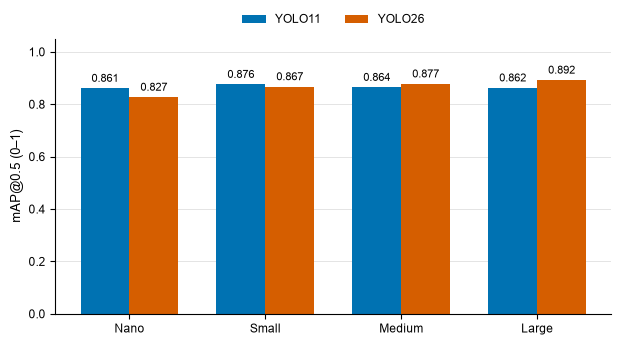

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
project_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "dataset" / "data.yaml").is_file() and (p / "models").is_dir()), None)
if project_root is None:
    raise FileNotFoundError("Open this notebook from inside the project repository.")
import sys
style_dir = str(project_root / "src")
if style_dir not in sys.path:
    sys.path.insert(0, style_dir)
from evaluation.plotting.comparison_figures import plot_historical_map50
from evaluation.plotting.style import configure_figures
configure_figures()
saved = json.loads((project_root / "models/comparisons/yolo11-vs-yolo26-map50.json").read_text())
variants = ("n", "s", "m", "l")
yolo11 = [saved["models"]["yolov11"][v]["map50"] for v in variants]
yolo26 = [saved["models"]["yolov26"][v]["map50"] for v in variants]
fig = plot_historical_map50(variants, yolo11, yolo26, project_root)
plt.show()


## Refresh the scores from Git tags

Saved historical metrics: /home/carol/urban-disaster-monitor/models/comparisons/yolo11-vs-yolo26-map50.json
{'YOLOv11': {'n': 0.86062, 's': 0.87554, 'm': 0.86423, 'l': 0.86212}, 'YOLOv26': {'n': 0.82672, 's': 0.86674, 'm': 0.87736, 'l': 0.89192}}


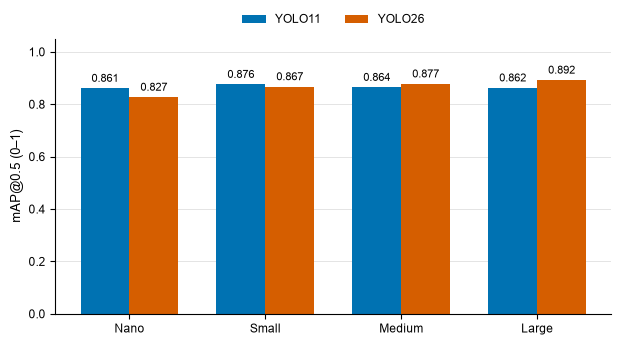

In [2]:
import json
import csv
from io import StringIO
from pathlib import Path
import subprocess

import matplotlib.pyplot as plt
import numpy as np

from pathlib import Path
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "dataset" / "data.yaml").is_file() and (p / "models").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the project repository.")

def latest_tag(prefix):
    tags = subprocess.check_output(["git", "tag", "--list", f"{prefix}-v*"], cwd=PROJECT_ROOT, text=True).splitlines()
    if not tags:
        raise FileNotFoundError(f"No Git tags found for {prefix}; clone the full repository with tags.")
    return sorted(tags, key=lambda tag: [int(part) for part in tag.rsplit("-v", 1)[-1].split(".")])[-1]

TAG_11 = latest_tag("yolo11")
TAG_26 = latest_tag("yolo26")
VARIANTS = tuple(v for v in ("n", "s", "m", "l") if (PROJECT_ROOT / "models" / f"yolov26{v}" / "results.csv").is_file())
METRIC_COLUMN = "metrics/mAP50(B)"

def best_map50_from_tag(tag, family, variant):
    artifact = f"models/{family}{variant}/results.csv"
    result = subprocess.run(
        ["git", "show", f"{tag}:{artifact}"],
        cwd=PROJECT_ROOT,
        check=True,
        capture_output=True,
        text=True,
    )
    rows = list(csv.DictReader(StringIO(result.stdout)))
    if not rows or METRIC_COLUMN not in rows[0]:
        raise KeyError(f"{METRIC_COLUMN} is missing from {tag}:{artifact}")
    return max(float(row[METRIC_COLUMN]) for row in rows)

yolo11_map50 = [best_map50_from_tag(TAG_11, "yolov11", variant) for variant in VARIANTS]
yolo26_map50 = [best_map50_from_tag(TAG_26, "yolov26", variant) for variant in VARIANTS]

cache_path = PROJECT_ROOT / "models" / "comparisons" / "yolo11-vs-yolo26-map50.json"
cache_path.parent.mkdir(parents=True, exist_ok=True)
cache_path.write_text(json.dumps({
    "metric": METRIC_COLUMN,
    "selection": "highest recorded validation mAP@0.5 in results.csv",
    "models": {
        family: {variant: {"map50": score, "source": f"{tag}:models/{family}{variant}/results.csv"}
                 for variant, score in zip(VARIANTS, scores)}
        for family, tag, scores in (("yolov11", TAG_11, yolo11_map50), ("yolov26", TAG_26, yolo26_map50))
    },
}, indent=2) + "\n")
print(f"Saved historical metrics: {cache_path}")

print({"YOLOv11": dict(zip(VARIANTS, yolo11_map50)), "YOLOv26": dict(zip(VARIANTS, yolo26_map50))})


import sys
style_dir = str(PROJECT_ROOT / "src")
if style_dir not in sys.path:
    sys.path.insert(0, style_dir)
from evaluation.plotting.comparison_figures import plot_historical_map50
from evaluation.plotting.style import configure_figures
configure_figures()
fig = plot_historical_map50(VARIANTS, yolo11_map50, yolo26_map50, PROJECT_ROOT)
plt.show()
